In [ ]:
import os
import pandas as pd
import numpy as np

# Load the California housing test dataset as requested
dataset_path = '/content/sample_data/california_housing_test.csv'
print(f"Loading dataset from: {dataset_path}")
df = pd.read_csv(dataset_path)

print(f"Dataset successfully loaded! Shape of dataset: {df.shape}")
display(df.head())


Loading dataset from: /content/sample_data/california_housing_test.csv
Dataset successfully loaded! Shape of dataset: (3000, 9)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-122.05,37.37,27.0,3885.0,661.0,1537.0,606.0,6.6085,344700.0
1,-118.30,34.26,43.0,1510.0,310.0,809.0,277.0,3.5990,176500.0
2,-117.81,33.78,27.0,3589.0,507.0,1484.0,495.0,5.7934,270500.0
3,-118.36,33.82,28.0,67.0,15.0,49.0,11.0,6.1359,330000.0
4,-119.67,36.33,19.0,1241.0,244.0,850.0,237.0,2.9375,81700.0


In [ ]:
if 'df' in globals():
    # Check for missing values
    missing_values = df.isnull().sum()
    missing_percentage = (df.isnull().sum() / len(df)) * 100
    missing_df = pd.DataFrame({'Missing Values': missing_values, 'Percentage (%)': missing_percentage})
    print("--- Missing Values Summary ---")
    display(missing_df)

    # Check for duplicate records
    duplicate_count = df.duplicated().sum()
    print(f"\n--- Duplicate Records Summary ---")
    print(f"Number of duplicate rows: {duplicate_count}")
else:
    print("Dataset 'df' is not loaded yet. Please run the first cell to load the data.")

--- Missing Values Summary ---


,Missing Values,Percentage (%)
longitude,0,0.0
latitude,0,0.0
housing_median_age,0,0.0
total_rooms,0,0.0
total_bedrooms,0,0.0
population,0,0.0
households,0,0.0
median_income,0,0.0
median_house_value,0,0.0



--- Duplicate Records Summary ---
Number of duplicate rows: 0


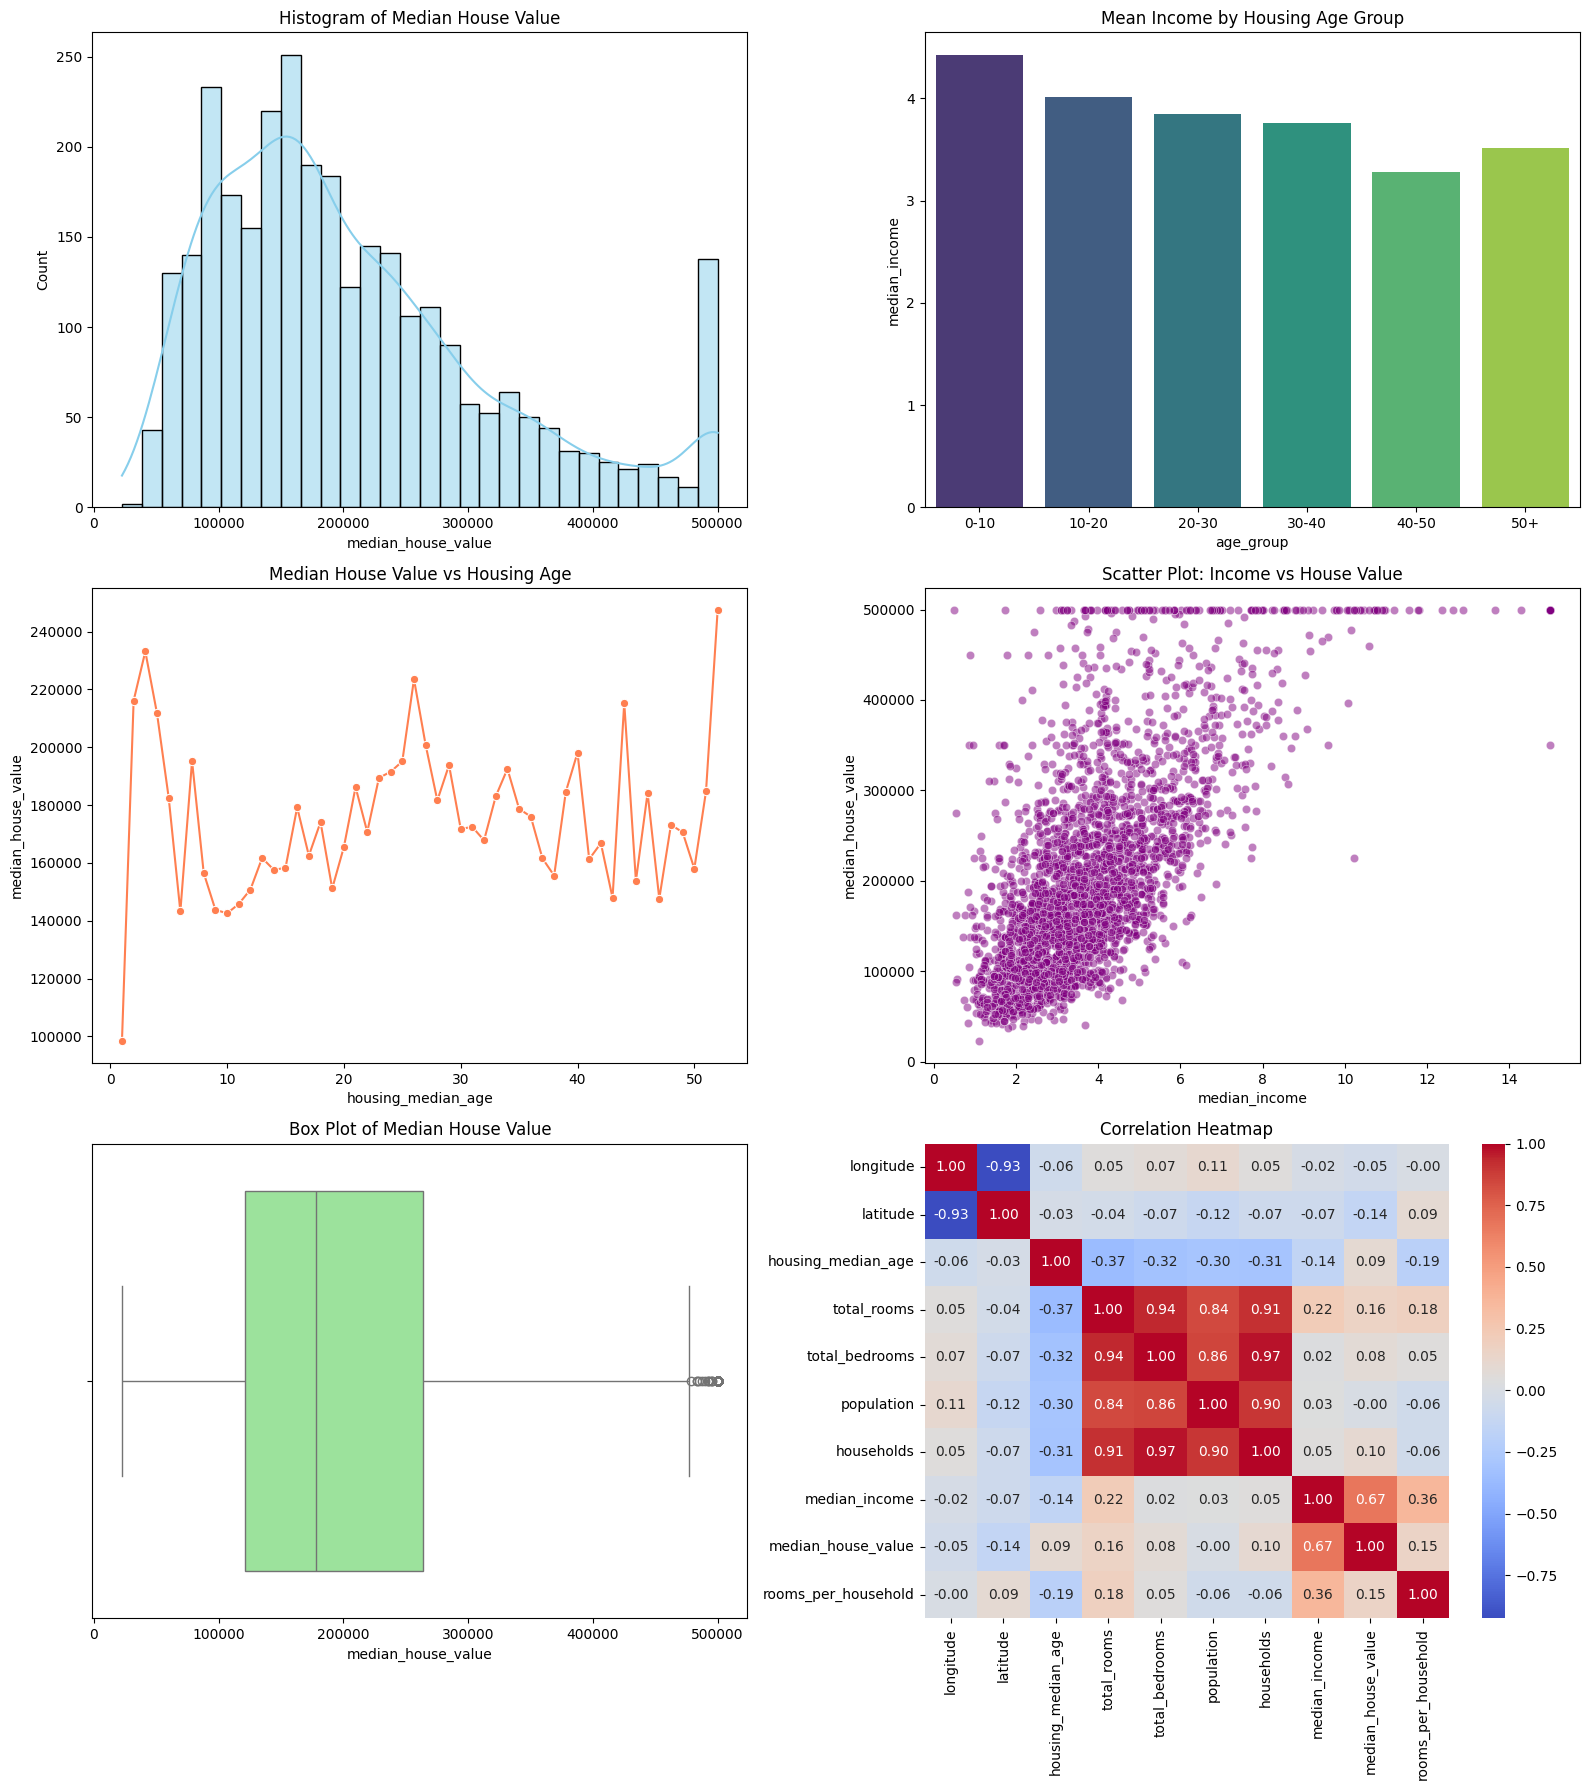

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

# Step 6: Visualizations using Matplotlib/Seaborn
fig, axes = plt.subplots(3, 2, figsize=(16, 18))

# 1. Histogram of Median House Value
sns.histplot(df['median_house_value'], bins=30, kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Histogram of Median House Value')

# 2. Bar Chart (Mean Income by Housing Median Age Groups with observed=False to fix warning)
df['age_group'] = pd.cut(df['housing_median_age'], bins=[0, 10, 20, 30, 40, 50, 100], labels=['0-10', '10-20', '20-30', '30-40', '40-50', '50+'])
age_income = df.groupby('age_group', observed=False)['median_income'].mean().reset_index()
sns.barplot(data=age_income, x='age_group', y='median_income', ax=axes[0, 1], hue='age_group', palette='viridis', legend=False)
axes[0, 1].set_title('Mean Income by Housing Age Group')

# 3. Line Chart (Median House Value by Housing Median Age)
age_value = df.groupby('housing_median_age')['median_house_value'].median().reset_index()
sns.lineplot(data=age_value, x='housing_median_age', y='median_house_value', ax=axes[1, 0], color='coral', marker='o')
axes[1, 0].set_title('Median House Value vs Housing Age')

# 4. Scatter Plot (Median Income vs Median House Value)
sns.scatterplot(data=df, x='median_income', y='median_house_value', alpha=0.5, ax=axes[1, 1], color='purple')
axes[1, 1].set_title('Scatter Plot: Income vs House Value')

# 5. Box Plot of Median House Value to detect outliers
sns.boxplot(x=df['median_house_value'], ax=axes[2, 0], color='lightgreen')
axes[2, 0].set_title('Box Plot of Median House Value')

# 6. Correlation Heatmap
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f', ax=axes[2, 1])
axes[2, 1].set_title('Correlation Heatmap')

plt.tight_layout()
plt.show()

In [31]:
import plotly.express as px

# Updated Step 7: Interactive Visualizations with pandas FutureWarning fixed
# 1. Interactive Histogram of Median House Value
fig_hist = px.histogram(df, x='median_house_value', nbins=50, title='Interactive Histogram of Median House Value', color_discrete_sequence=['teal'])
fig_hist.show()

# 2. Interactive Scatter Plot (Median Income vs Median House Value)
fig_scatter = px.scatter(df, x='median_income', y='median_house_value', hover_data=['housing_median_age', 'population'], title='Interactive Scatter: Income vs House Value', color='housing_median_age')
fig_scatter.show()

# 3. Interactive Bar Chart (Average Rooms per Household across Housing Age Groups with observed=False to fix warning)
df['rooms_per_household'] = df['total_rooms'] / df['households']
age_rooms = df.groupby('age_group', observed=False)['rooms_per_household'].mean().reset_index()
fig_bar = px.bar(age_rooms, x='age_group', y='rooms_per_household', title='Interactive Bar: Average Rooms per Household by Housing Age Group', color='rooms_per_household')
fig_bar.show()

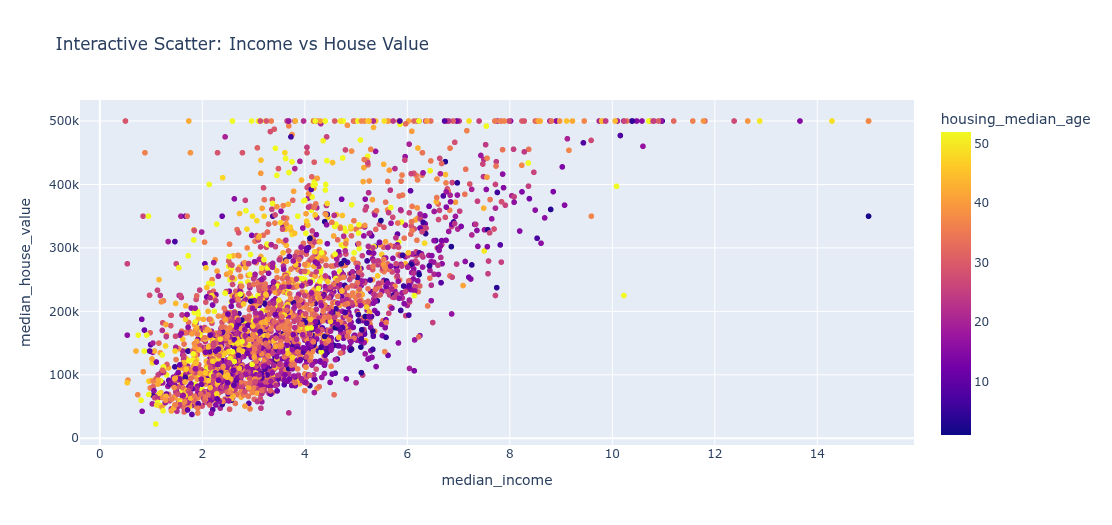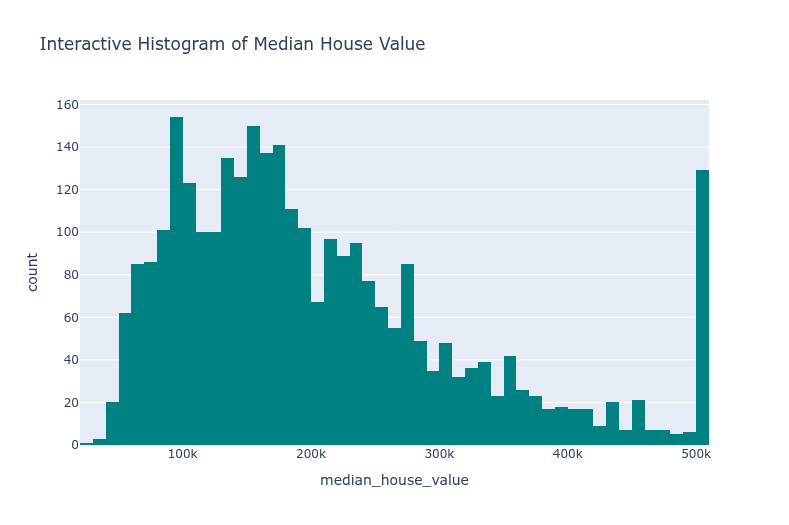

In [34]:
from sklearn.preprocessing import StandardScaler

# Step 8: Feature Engineering
# Creating 3 new features
# Feature 1: Rooms per household
df['rooms_per_household'] = df['total_rooms'] / df['households']

# Feature 2: Bedrooms per room ratio
df['bedrooms_per_room'] = df['total_bedrooms'] / df['total_rooms']

# Feature 3: Population per household
df['population_per_household'] = df['population'] / df['households']

# Numerical Scaling on engineered features and median income
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df[['rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'median_income']])
scaled_cols = ['scaled_rooms_hh', 'scaled_bedrooms_room', 'scaled_pop_hh', 'scaled_income']
df[scaled_cols] = scaled_features

print("--- Dataset with Engineered and Scaled Features ---")
display(df[['rooms_per_household', 'bedrooms_per_room', 'population_per_household'] + scaled_cols].head())

--- Dataset with Engineered and Scaled Features ---


,rooms_per_household,bedrooms_per_room,population_per_household,scaled_rooms_hh,scaled_bedrooms_room,scaled_pop_hh,scaled_income
0,6.410891,0.170142,2.536304,0.441088,-0.747222,-0.117123,1.510745
1,5.451264,0.205298,2.920578,0.019633,-0.153717,-0.026922,-0.112324
2,7.250505,0.141265,2.997980,0.809835,-1.234711,-0.008753,1.071149
3,6.090909,0.223881,4.454545,0.300557,0.159991,0.333149,1.255865
4,5.236287,0.196616,3.586498,-0.074782,-0.300291,0.129391,-0.469081


In [ ]:
# Step 2: Python and NumPy Operations on the California Housing Data
# Extract numerical columns as NumPy arrays
house_values = df['median_house_value'].to_numpy()
incomes = df['median_income'].to_numpy()

# Perform array operations & calculate descriptive statistics using NumPy
stats = {
    "Mean": np.mean(house_values),
    "Median": np.median(house_values),
    "Std Dev": np.std(house_values),
    "Min": np.min(house_values),
    "Max": np.max(house_values),
    "25th Percentile": np.percentile(house_values, 25),
    "75th Percentile": np.percentile(house_values, 75)
}

print("--- NumPy Statistics for Median House Value ---")
for stat, val in stats.items():
    print(f"{stat}: {val:,.2f}")

# Array slicing and arithmetic operation (e.g., calculating House Value to Income ratio)
ratio = house_values / (incomes * 10000) # scaling incomes to compare
print(f"\nSample calculated Ratio (Value / Income*10k) - First 5 rows:", ratio[:5])

--- NumPy Statistics for Median House Value ---
Mean: 205,846.27
Median: 177,650.00
Std Dev: 113,100.83
Min: 22,500.00
Max: 500,001.00
25th Percentile: 121,200.00
75th Percentile: 263,975.00

Sample calculated Ratio (Value / Income*10k) - First 5 rows: [5.21600968 4.90414004 4.66910622 5.37818413 2.7812766 ]


In [ ]:
# Step 5: Exploratory Data Analysis & Descriptive Statistical Analysis
print("--- Dataset Summary Statistics (Pandas) ---")
display(df.describe())

# Investigate correlations restricting to numeric columns only
print("\n--- Correlation Matrix ---")
correlation_matrix = df.corr(numeric_only=True)
display(correlation_matrix)

--- Dataset Summary Statistics (Pandas) ---


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,rooms_per_household,bedrooms_per_room,population_per_household,scaled_rooms_hh,scaled_bedrooms_room,scaled_pop_hh,scaled_income
count,3000.000000,3000.00000,3000.000000,3000.000000,3000.000000,3000.000000,3000.00000,3000.000000,3000.00000,3000.000000,3000.000000,3000.000000,3.000000e+03,3.000000e+03,3.000000e+03,3.000000e+03
mean,-119.589200,35.63539,28.845333,2599.578667,529.950667,1402.798667,489.91200,3.807272,205846.27500,5.406560,0.214403,3.035270,-1.385558e-16,5.068538e-16,3.197442e-17,1.859253e-16
std,1.994936,2.12967,12.555396,2155.593332,415.654368,1030.543012,365.42271,1.854512,113119.68747,2.277318,0.059245,4.260889,1.000167e+00,1.000167e+00,1.000167e+00,1.000167e+00
min,-124.180000,32.56000,1.000000,6.000000,2.000000,5.000000,2.00000,0.499900,22500.00000,1.553030,0.100000,1.066176,-1.692417e+00,-1.931339e+00,-4.622091e-01,-1.783716e+00
25%,-121.810000,33.93000,18.000000,1401.000000,291.000000,780.000000,273.00000,2.544000,121200.00000,4.421021,0.176218,2.416424,-4.328350e-01,-6.446324e-01,-1.452629e-01,-6.813019e-01
50%,-118.485000,34.27000,29.000000,2106.000000,437.000000,1155.000000,409.50000,3.487150,177650.00000,5.204142,0.204459,2.842197,-8.889930e-02,-1.678778e-01,-4.532040e-02,-1.726466e-01
75%,-118.020000,37.69000,37.000000,3129.000000,636.000000,1742.750000,597.25000,4.656475,263975.00000,6.043361,0.239297,3.306515,2.796741e-01,4.202458e-01,6.366977e-02,4.579884e-01
max,-114.490000,41.92000,52.000000,30450.000000,5419.000000,11935.000000,4930.00000,15.000100,500001.00000,62.422222,1.000000,230.172414,2.504049e+01,1.326230e+01,5.331634e+01,6.036464e+00



--- Correlation Matrix ---


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,rooms_per_household,bedrooms_per_room,population_per_household,scaled_rooms_hh,scaled_bedrooms_room,scaled_pop_hh,scaled_income
longitude,1.000000,-0.925017,-0.064203,0.049865,0.070869,0.111572,0.051062,-0.018701,-0.050662,-0.003341,0.086410,0.017611,-0.003341,0.086410,0.017611,-0.018701
latitude,-0.925017,1.000000,-0.025143,-0.039632,-0.068245,-0.117318,-0.068296,-0.072363,-0.138428,0.094347,-0.112768,-0.003522,0.094347,-0.112768,-0.003522,-0.072363
housing_median_age,-0.064203,-0.025143,1.000000,-0.367850,-0.323154,-0.299888,-0.305171,-0.144315,0.091409,-0.192103,0.150779,0.035475,-0.192103,0.150779,0.035475,-0.144315
total_rooms,0.049865,-0.039632,-0.367850,1.000000,0.937749,0.838867,0.914116,0.221249,0.160427,0.181920,-0.214685,-0.048283,0.181920,-0.214685,-0.048283,0.221249
total_bedrooms,0.070869,-0.068245,-0.323154,0.937749,1.000000,0.856387,0.970758,0.024025,0.082279,0.050271,0.038412,-0.055736,0.050271,0.038412,-0.055736,0.024025
population,0.111572,-0.117318,-0.299888,0.838867,0.856387,1.000000,0.895530,0.032361,-0.001192,-0.058487,0.002244,0.130885,-0.058487,0.002244,0.130885,0.032361
households,0.051062,-0.068296,-0.305171,0.914116,0.970758,0.895530,1.000000,0.048625,0.100176,-0.059093,0.021688,-0.054106,-0.059093,0.021688,-0.054106,0.048625
median_income,-0.018701,-0.072363,-0.144315,0.221249,0.024025,0.032361,0.048625,1.000000,0.672695,0.363624,-0.608383,0.005594,0.363624,-0.608383,0.005594,1.000000
median_house_value,-0.050662,-0.138428,0.091409,0.160427,0.082279,-0.001192,0.100176,0.672695,1.000000,0.153429,-0.246313,-0.045272,0.153429,-0.246313,-0.045272,0.672695
rooms_per_household,-0.003341,0.094347,-0.192103,0.181920,0.050271,-0.058487,-0.059093,0.363624,0.153429,1.000000,-0.452306,0.004960,1.000000,-0.452306,0.004960,0.363624
